# 03 - Benchmark: Pandas vs PySpark
**HMDA 2024 project - Group 7.** Measures how long Pandas and PySpark take to do the **same analytical work** on the cleaned data (`hmda_clean_v1`), and checks that both give the **same results**.

**What is measured**
- **Workload:** 7 group-by aggregations (denial counts by state, region, metro status, loan type, MSA and region x loan type, plus mean income, loan amount, CLTV and loan-to-income by state x denied). This is the core of RQ1 and RQ2.
- **Data size:** 25%, 50% and 100% of the 3,140,857 cleaned records. Both tools read the **same files**.
- **Runs:** 5 per configuration, every run reported.
- **Spark setup is separated from run time:** session start-up is measured once, then excluded from the run times.
- **Cache vs no cache:** Spark is run without cache (every run reads the Parquet file again) and with `cache()` (the cache fill is reported separately from the computation).
- **Spark settings:** Spark is run with its **default** of 200 shuffle partitions and with a **tuned** setting of 8 (`spark.sql.shuffle.partitions`). With 2 CPU cores and a small table, 200 partitions may add scheduling overhead; the tuned runs test that.

**How to use:** run all cells from top to bottom (about 10-20 minutes). Run it in **one Colab session** so that every number comes from the same machine. Do not run anything else at the same time.

## Step 1. Mount Drive, install PySpark, configuration

In [2]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q pyspark==4.0.5   # same version as requirements.txt

import os, time, json, shutil, platform, statistics
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

DRIVE_DIR  = "/content/drive/MyDrive/hmda"
CLEAN_PATH = f"{DRIVE_DIR}/hmda_clean_v1/hmda_clean_v1.parquet"
RESULTS    = f"{DRIVE_DIR}/results"
FIG_DIR    = f"{RESULTS}/figures"
LOCAL_DIR  = "/content/bench_data"          # local copy: both tools read from the same local disk, not from Drive
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(LOCAL_DIR, exist_ok=True)
assert os.path.exists(CLEAN_PATH), "hmda_clean_v1.parquet not found - run 01b first"

RUNS   = 5                      # runs per configuration (the instructor asked for 5)
SHUFFLE_SETTINGS = [200, 8]     # spark.sql.shuffle.partitions: 200 = Spark default, 8 = tuned for a small table on 2 cores
SCALES = [25, 50, 100]          # percent of the cleaned records
COLS = ["denied", "state_code", "census_region", "msa_md_clean", "metro_flag", "loan_type",
        "income", "loan_amount", "combined_loan_to_value_ratio", "loan_to_income"]
GROUPS = {"state": ["state_code"], "region": ["census_region"], "metro": ["metro_flag"],
          "loan_type": ["loan_type"], "msa": ["msa_md_clean"], "region_x_loan": ["census_region", "loan_type"]}
FIN_COLS = ["income", "loan_amount", "combined_loan_to_value_ratio", "loan_to_income"]
print("Configuration OK")

Mounted at /content/drive
Configuration OK


## Step 2. Prepare the data files (25%, 50%, 100%)
The same rows are written once to the local disk and then read by **both** tools, so the comparison is on identical data. Preparing the files is not part of the timings.

In [3]:
full = pd.read_parquet(CLEAN_PATH, columns=COLS)
assert len(full) == 3140857 and full["denied"].sum() == 276604, "Numbers do not match the cleaned data"
PATHS = {}
for s in SCALES:
    d = full if s == 100 else full.sample(frac=s / 100, random_state=42)
    PATHS[s] = f"{LOCAL_DIR}/clean_{s}.parquet"
    d.to_parquet(PATHS[s], index=False)
    print(f"{s:>3}%  {len(d):>9,} rows  {os.path.getsize(PATHS[s]) / 1e6:6.1f} MB")
del full

 25%    785,214 rows     7.8 MB
 50%  1,570,428 rows    15.6 MB
100%  3,140,857 rows    29.3 MB


## Step 3. The workload (same work in both tools)
Each function returns plain Python dictionaries so the two tools can be compared exactly. The timer covers everything from reading the result of the aggregation to building the dictionary.

In [4]:
def _key(idx):
    return tuple(str(k) for k in (idx if isinstance(idx, tuple) else (idx,)))

def pandas_workload(df):
    res = {}
    for name, keys in GROUPS.items():
        g = df.groupby(keys, observed=True, dropna=False)["denied"].agg(["size", "sum"])
        res[name] = {_key(i): (int(n), int(d)) for i, n, d in zip(g.index, g["size"], g["sum"])}
    g = df.groupby(["state_code", "denied"], observed=True, dropna=False).agg(
        n=("denied", "size"), **{c: (c, "mean") for c in FIN_COLS})
    res["fin_by_state_denied"] = {_key(i): (int(r["n"]),) + tuple(float(r[c]) for c in FIN_COLS)
                                  for i, (_, r) in zip(g.index, g.iterrows())}
    return res

def spark_workload(sdf):
    res = {}
    for name, keys in GROUPS.items():
        rows = sdf.groupBy(*keys).agg(F.count(F.lit(1)).alias("n"), F.sum("denied").alias("d")).collect()
        res[name] = {tuple(str(r[k]) for k in keys): (int(r["n"]), int(r["d"])) for r in rows}
    rows = (sdf.groupBy("state_code", "denied")
               .agg(F.count(F.lit(1)).alias("n"), *[F.avg(c).alias(c) for c in FIN_COLS]).collect())
    res["fin_by_state_denied"] = {(str(r["state_code"]), str(r["denied"])):
                                  (int(r["n"]),) + tuple(float(r[c]) if r[c] is not None else float("nan") for c in FIN_COLS)
                                  for r in rows}
    return res
print("Workload defined: 7 aggregations")

Workload defined: 7 aggregations


## Step 4. Spark setup (measured once, kept separate from the run times)
Start-up includes importing PySpark, creating the session and running a first small job (this starts the JVM and the executor). It can only be measured **cold once** per session, so it is reported on its own and is **not** part of any run time below.

In [5]:
t0 = time.perf_counter()
from pyspark.sql import SparkSession, functions as F
import pyspark
spark = (SparkSession.builder.master("local[*]")
         .config("spark.driver.memory", "8g")
         .appName("hmda_benchmark").getOrCreate())
spark.range(1000).groupBy().count().collect()
SETUP_SECONDS = time.perf_counter() - t0
print(f"Spark {pyspark.__version__} ready. Setup (cold start): {SETUP_SECONDS:.1f}s")

Spark 4.0.5 ready. Setup (cold start): 25.8s


## Step 5. Correctness: do the two tools give the same results?
Checked on the 100% data for all 7 outputs, for Spark with both settings (200 and 8 partitions). Counts must be **exactly equal**; means are compared with a relative tolerance of 1e-9. This is the correctness part of the comparison.

In [6]:
def same(x, y, tol=1e-9):
    if isinstance(x, float) or isinstance(y, float):
        if np.isnan(x) and np.isnan(y):
            return True
        return abs(x - y) <= tol * max(1.0, abs(y))
    return x == y

pdf_full = pd.read_parquet(PATHS[100], columns=COLS)
r_pd = pandas_workload(pdf_full)
del pdf_full
r_sp = spark_workload(spark.read.parquet(PATHS[100]).select(*COLS))              # Spark default (200 shuffle partitions)
spark.conf.set("spark.sql.shuffle.partitions", str(SHUFFLE_SETTINGS[-1]))
r_sp_tuned = spark_workload(spark.read.parquet(PATHS[100]).select(*COLS))        # tuned setting
spark.conf.set("spark.sql.shuffle.partitions", "200")                            # back to the default

rows, bad = [], 0
for name in r_pd:
    a, b_ = r_pd[name], r_sp[name]
    c = r_sp_tuned[name]
    ok = (set(a) == set(b_) and all(all(same(u, v) for u, v in zip(a[k], b_[k])) for k in a)
          and set(a) == set(c) and all(all(same(u, v) for u, v in zip(a[k], c[k])) for k in a))
    bad += (not ok)
    rows.append({"output": name, "groups": len(a), "pandas_equals_spark_default_and_tuned": ok})
    print(f"{'OK       ' if ok else 'MISMATCH '} {name:22s} groups={len(a):>5,}")
pd.DataFrame(rows).to_csv(f"{RESULTS}/benchmark_correctness.csv", index=False)
assert bad == 0, "Pandas and Spark results differ - do not use the timings"
print("\n=> PANDAS = SPARK for all 7 outputs")

OK        state                  groups=   55
OK        region                 groups=    6
OK        metro                  groups=    2
OK        loan_type              groups=    4
OK        msa                    groups=  418
OK        region_x_loan          groups=   24
OK        fin_by_state_denied    groups=  110

=> PANDAS = SPARK for all 7 outputs


## Step 6. Timing (5 runs per configuration)
Five configurations, each run `RUNS` times on each data size:
1. **Pandas:** read the Parquet file, then compute. Reported as *load* + *compute*.
2. **Spark-200 (no cache) and Spark-8 (no cache):** every run reads the Parquet file again and computes (Spark is lazy, so reading and computing cannot be separated; the whole run is reported). 200 is Spark's default number of shuffle partitions, 8 is the tuned value.
3. **Spark-200 (cache) and Spark-8 (cache):** `cache()` the table, fill it with one `count()` (*fill*), then compute on the cached table. Fill and compute are reported separately.

Every run is saved, including the first (the first Spark run is usually the slowest). This cell takes the longest.

In [7]:
runs = []
for s in SCALES:
    # 1) Pandas
    for r in range(1, RUNS + 1):
        t0 = time.perf_counter()
        d = pd.read_parquet(PATHS[s], columns=COLS)
        t1 = time.perf_counter()
        pandas_workload(d)
        t2 = time.perf_counter()
        del d
        runs.append(dict(config="Pandas", scale=s, run=r, load_or_fill=t1 - t0, compute=t2 - t1, total=t2 - t0))
    for sp in SHUFFLE_SETTINGS:
        spark.conf.set("spark.sql.shuffle.partitions", str(sp))
        spark.catalog.clearCache()
        # 2) Spark without cache
        for r in range(1, RUNS + 1):
            t0 = time.perf_counter()
            spark_workload(spark.read.parquet(PATHS[s]).select(*COLS))
            t = time.perf_counter() - t0
            runs.append(dict(config=f"Spark-{sp} (no cache)", scale=s, run=r, load_or_fill=np.nan, compute=t, total=t))
        # 3) Spark with cache
        for r in range(1, RUNS + 1):
            sdf = spark.read.parquet(PATHS[s]).select(*COLS).cache()
            t0 = time.perf_counter(); sdf.count(); t1 = time.perf_counter()
            spark_workload(sdf); t2 = time.perf_counter()
            sdf.unpersist(blocking=True)
            runs.append(dict(config=f"Spark-{sp} (cache)", scale=s, run=r, load_or_fill=t1 - t0, compute=t2 - t1, total=t2 - t0))
    print(f"{s}% done")
spark.conf.set("spark.sql.shuffle.partitions", "200")
runs = pd.DataFrame(runs)
runs.to_csv(f"{RESULTS}/benchmark_runs.csv", index=False)
print(runs.round(2).to_string(index=False))

25% done
50% done
100% done
              config  scale  run  load_or_fill  compute  total
              Pandas     25    1          0.08     0.37   0.45
              Pandas     25    2          0.07     0.23   0.31
              Pandas     25    3          0.08     0.23   0.30
              Pandas     25    4          0.08     0.25   0.32
              Pandas     25    5          0.08     0.23   0.30
Spark-200 (no cache)     25    1           NaN     3.59   3.59
Spark-200 (no cache)     25    2           NaN     5.06   5.06
Spark-200 (no cache)     25    3           NaN     2.89   2.89
Spark-200 (no cache)     25    4           NaN     2.56   2.56
Spark-200 (no cache)     25    5           NaN     2.39   2.39
   Spark-200 (cache)     25    1          5.46     5.10  10.57
   Spark-200 (cache)     25    2          2.82     2.79   5.61
   Spark-200 (cache)     25    3          4.35     2.82   7.17
   Spark-200 (cache)     25    4          2.59     2.47   5.07
   Spark-200 (cache)     25

## Step 7. Summary table and speedup
**Speedup = Pandas median total time / Spark median total time.** A value below 1 means Pandas was faster. For *Spark (cache)* the total includes the cache fill; the compute-only time is shown too.

In [8]:
order = ["Pandas"] + [f"Spark-{sp} ({c})" for sp in SHUFFLE_SETTINGS for c in ("no cache", "cache")]
g = runs.groupby(["scale", "config"])
summary = g["total"].agg(median="median", mean="mean", min="min", max="max").round(2)
summary["compute_median"] = g["compute"].median().round(2)
summary = summary.reset_index()
summary["config"] = pd.Categorical(summary["config"], order, ordered=True)
summary = summary.sort_values(["scale", "config"]).reset_index(drop=True)
pandas_med = summary[summary["config"] == "Pandas"].set_index("scale")["median"]
summary["speedup_vs_pandas"] = (summary["scale"].map(pandas_med) / summary["median"]).round(2)
summary.to_csv(f"{RESULTS}/benchmark_summary.csv", index=False)
print("Seconds per run (5 runs). Spark setup (cold start, not included): %.1fs" % SETUP_SECONDS)
print(summary.to_string(index=False))

Seconds per run (5 runs). Spark setup (cold start, not included): 25.8s
 scale               config  median  mean   min   max  compute_median  speedup_vs_pandas
    25               Pandas    0.31  0.34  0.30  0.45            0.23               1.00
    25 Spark-200 (no cache)    2.89  3.30  2.39  5.06            2.89               0.11
    25    Spark-200 (cache)    6.18  6.92  5.07 10.57            2.82               0.05
    25   Spark-8 (no cache)    2.10  2.23  1.92  2.93            2.10               0.15
    25      Spark-8 (cache)    5.14  5.36  4.42  6.93            1.93               0.06
    50               Pandas    0.65  0.65  0.62  0.66            0.48               1.00
    50 Spark-200 (no cache)    2.86  3.25  2.62  4.87            2.86               0.23
    50    Spark-200 (cache)    9.35  8.71  7.65  9.45            3.05               0.07
    50   Spark-8 (no cache)    2.47  2.89  2.26  3.72            2.47               0.26
    50      Spark-8 (cache)    8.66  8

## Step 8. Chart

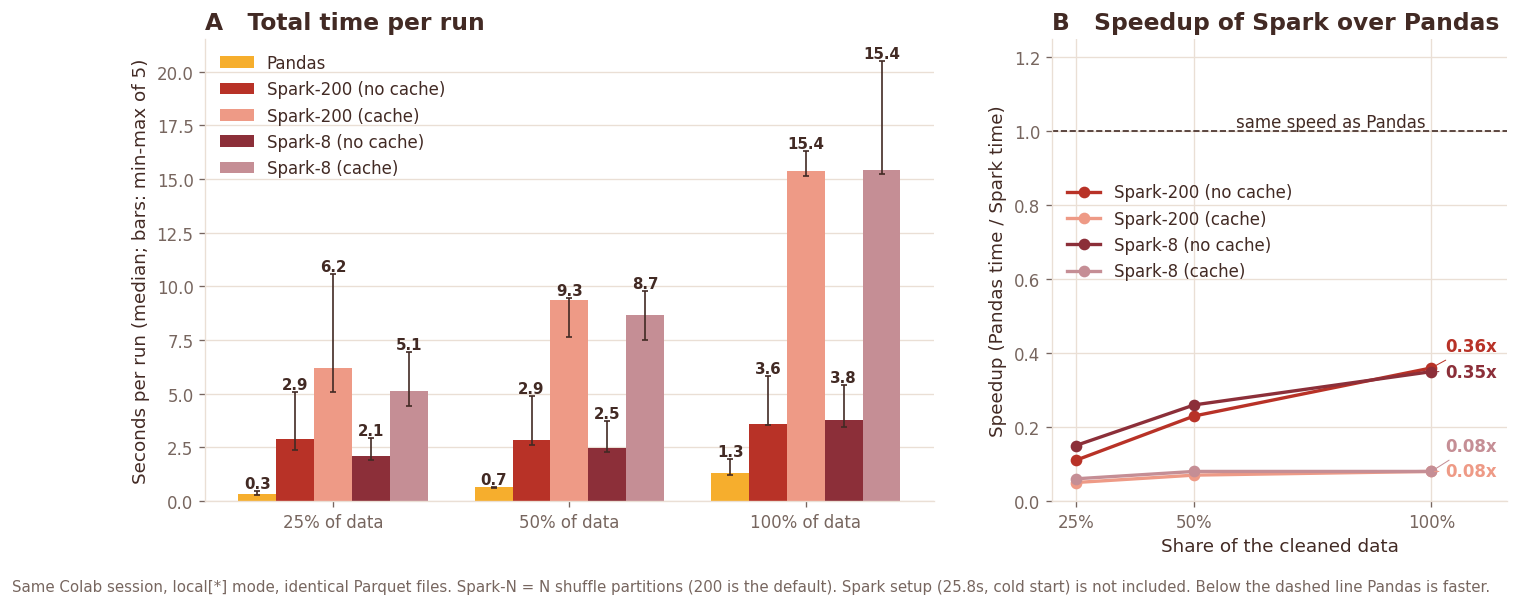

In [9]:
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # DejaVu has no 'semibold' file: Matplotlib draws bold
# GROUP 7 - OFFICIAL COLOR SYSTEM (same as notebooks 02, 04, 05)
G7 = {"amber": "#F6AE2D", "deep_red": "#B83227", "burgundy": "#8C2F39", "text": "#422A24", "secondary": "#77665F", "grid": "#EADFD5"}
TXT, SEC = G7["text"], G7["secondary"]
mpl.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "axes.titlesize": 14, "axes.titleweight": "bold",
                     "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10,
                     "figure.dpi": 120, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": G7["grid"], "axes.labelcolor": TXT, "text.color": TXT,
                     "xtick.color": SEC, "ytick.color": SEC, "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.grid": True, "grid.color": G7["grid"], "grid.linewidth": 0.8, "axes.axisbelow": True})
# Pandas = amber; Spark with 200 partitions = deep red; Spark with 8 partitions = burgundy; light tint = with cache
COL = {"Pandas": G7["amber"], "Spark-200 (no cache)": G7["deep_red"], "Spark-200 (cache)": "#EE9A86",
       "Spark-8 (no cache)": G7["burgundy"], "Spark-8 (cache)": "#C58E95"}
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.6, 1]})
w = 0.16
for j, cfg in enumerate(order):
    d = summary[summary["config"] == cfg].set_index("scale").reindex(SCALES)
    x = np.arange(len(SCALES)) + (j - (len(order) - 1) / 2) * w
    ax1.bar(x, d["median"], width=w, color=COL[cfg], label=cfg,
            yerr=[d["median"] - d["min"], d["max"] - d["median"]], error_kw={"ecolor": TXT, "elinewidth": 1, "capsize": 2})
    for xi, v, top in zip(x, d["median"], d["max"]):
        ax1.text(xi, top, f"{v:.1f}", ha="center", va="bottom", fontsize=9, fontweight="semibold")
ax1.set_xticks(range(len(SCALES))); ax1.set_xticklabels([f"{s}% of data" for s in SCALES])
ax1.set_ylabel("Seconds per run (median; bars: min-max of 5)")
ax1.set_title("A   Total time per run", loc="left"); ax1.legend(frameon=False, fontsize=10, loc="upper left"); ax1.grid(axis="x", visible=False)
ends = {}
for cfg in order[1:]:
    d = summary[summary["config"] == cfg].set_index("scale").reindex(SCALES)
    ax2.plot(SCALES, d["speedup_vs_pandas"], marker="o", color=COL[cfg], label=cfg, lw=2)
    ends[cfg] = d["speedup_vs_pandas"].iloc[-1]
ymax = max(1.25, 1.2 * summary["speedup_vs_pandas"].max())
ax2.set_ylim(0, ymax)
gap, ylab = 0.055 * ymax, {}
for cfg, v in sorted(ends.items(), key=lambda kv: kv[1]):     # spread end labels so they do not overlap
    ylab[cfg] = v if not ylab else max(v, max(ylab.values()) + gap)
for cfg, v in ends.items():
    ax2.annotate(f"{v:.2f}x", (SCALES[-1], v), xytext=(SCALES[-1] + 3, ylab[cfg]), textcoords="data", va="center", fontsize=10, fontweight="semibold",
                 color=COL[cfg], arrowprops=dict(arrowstyle="-", color=COL[cfg], lw=0.6))
ax2.axhline(1, color=TXT, ls="--", lw=1)
ax2.text(SCALES[-1], 1, "same speed as Pandas ", va="bottom", ha="right", fontsize=10, color=TXT)
ax2.set_xticks(SCALES); ax2.set_xticklabels([f"{s}%" for s in SCALES]); ax2.set_xlim(SCALES[0] - 5, SCALES[-1] + 16)
ax2.set_xlabel("Share of the cleaned data"); ax2.set_ylabel("Speedup (Pandas time / Spark time)")
ax2.set_title("B   Speedup of Spark over Pandas", loc="left"); ax2.legend(frameon=False, fontsize=10, loc="upper left", bbox_to_anchor=(0, 0.72))
fig.text(0.01, -0.02, f"Same Colab session, local[*] mode, identical Parquet files. Spark-N = N shuffle partitions (200 is the default). Spark setup ({SETUP_SECONDS:.1f}s, cold start) is not included. Below the dashed line Pandas is faster.",
         fontsize=9, color=SEC, ha="left", va="top")
fig.savefig(f"{FIG_DIR}/benchmark.png", bbox_inches="tight", facecolor="white")
plt.show()

## Step 9. Save the environment (needed to interpret the timings)

In [10]:
try:
    import psutil; ram_gb = round(psutil.virtual_memory().total / 1e9, 1)
except Exception:
    ram_gb = None
env = {"python": platform.python_version(), "pandas": pd.__version__, "pyspark": pyspark.__version__,
       "cpu_count": os.cpu_count(), "ram_gb": ram_gb, "spark_master": "local[*]", "spark_driver_memory": "8g",
       "spark_shuffle_partitions_default": 200, "spark_shuffle_partitions_tested": SHUFFLE_SETTINGS,
       "runs_per_config": RUNS, "scales_percent": SCALES, "spark_setup_cold_seconds": round(SETUP_SECONDS, 2)}
with open(f"{RESULTS}/benchmark_env.json", "w") as fh:
    json.dump(env, fh, indent=2)
print(json.dumps(env, indent=2))
print("Saved: benchmark_runs.csv, benchmark_summary.csv, benchmark_correctness.csv, benchmark_env.json, figures/benchmark.png")

{
  "python": "3.13.18",
  "pandas": "2.2.3",
  "pyspark": "4.0.5",
  "cpu_count": 2,
  "ram_gb": 13.6,
  "spark_master": "local[*]",
  "spark_driver_memory": "8g",
  "spark_shuffle_partitions_default": 200,
  "spark_shuffle_partitions_tested": [
    200,
    8
  ],
  "runs_per_config": 5,
  "scales_percent": [
    25,
    50,
    100
  ],
  "spark_setup_cold_seconds": 25.76
}
Saved: benchmark_runs.csv, benchmark_summary.csv, benchmark_correctness.csv, benchmark_env.json, figures/benchmark.png


## How to read the result
- **Correctness:** Step 5 must show *PANDAS = SPARK for all 7 outputs*.
- **Speed:** use the **median** of the 5 runs and report the range. State the Spark setup time separately.
- **Spark settings:** compare *Spark-200* (default) with *Spark-8* (tuned). If Spark-8 is clearly faster, the default number of shuffle partitions is part of the overhead on a small table; if not, the overhead comes from elsewhere. Report which one you observe.
- Spark in `local[*]` mode runs on **one machine**, so it is **not guaranteed to be faster** than Pandas. Report the numbers as measured and explain them (for example start-up and scheduling overhead against the amount of data), do not assume the result in advance.
- Limits of this benchmark: one Colab machine, one workload (aggregations on the cleaned data), the operating system may cache the Parquet files after the first read, and Spark start-up can only be measured cold once per session.